In [1]:
!pip install rdkit

In [2]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, AllChem, rdFingerprintGenerator
from sklearn.model_selection import train_test_split, cross_validate, GroupKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
import matplotlib.pyplot as plt

In [3]:
path = ('/content/delaney.csv')

In [4]:
df = pd.read_csv(path)
df

,Compound ID,measured log(solubility:mol/L),ESOL predicted log(solubility:mol/L),SMILES
0,"1,1,1,2-Tetrachloroethane",-2.180,-2.794,ClCC(Cl)(Cl)Cl
1,"1,1,1-Trichloroethane",-2.000,-2.232,CC(Cl)(Cl)Cl
2,"1,1,2,2-Tetrachloroethane",-1.740,-2.549,ClC(Cl)C(Cl)Cl
3,"1,1,2-Trichloroethane",-1.480,-1.961,ClCC(Cl)Cl
4,"1,1,2-Trichlorotrifluoroethane",-3.040,-3.077,FC(F)(Cl)C(F)(Cl)Cl
...,...,...,...,...
1139,vamidothion,1.144,-1.446,CNC(=O)C(C)SCCSP(=O)(OC)(OC)
1140,Vinclozolin,-4.925,-4.377,CC1(OC(=O)N(C1=O)c2cc(Cl)cc(Cl)c2)C=C
1141,Warfarin,-3.893,-3.913,CC(=O)CC(c1ccccc1)c3c(O)c2ccccc2oc3=O
1142,Xipamide,-3.790,-3.642,Cc1cccc(C)c1NC(=O)c2cc(c(Cl)cc2O)S(N)(=O)=O


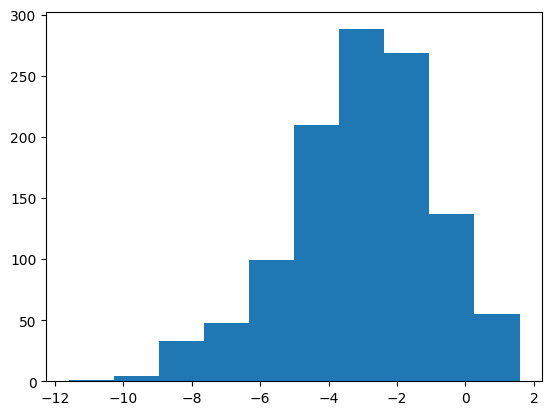

In [5]:
plt.hist(df['measured log(solubility:mol/L)'])
plt.show()

In [6]:
def calculate_delaney_descriptors(smiles_list):
    feats_list = []
    for smiles in smiles_list:
        mol = Chem.MolFromSmiles(smiles)
        logp = Descriptors.MolLogP(mol)
        mw = Descriptors.MolWt(mol)
        num_rot_bonds = Descriptors.NumRotatableBonds(mol)

        aromatic_atoms = sum(1 for atom in mol.GetAtoms() if atom.GetIsAromatic())
        heavy_atoms = mol.GetNumHeavyAtoms()
        aromatic_proportion = aromatic_atoms / heavy_atoms if heavy_atoms > 0 else 0

        feats_list.append({
            'MolLogP': logp,
            'MolWt': mw,
            'NumRotatableBonds': num_rot_bonds,
            'AromaticProportion': aromatic_proportion
        })
    return pd.DataFrame(feats_list)

In [7]:
X = calculate_delaney_descriptors(df['SMILES'])
y = df['measured log(solubility:mol/L)']
model = RandomForestRegressor()

In [8]:
X

,MolLogP,MolWt,NumRotatableBonds,AromaticProportion
0,2.59540,167.850,0,0.000000
1,2.37650,133.405,0,0.000000
2,2.59380,167.850,1,0.000000
3,2.02890,133.405,1,0.000000
4,2.91890,187.375,1,0.000000
...,...,...,...,...
1139,1.98820,287.343,8,0.000000
1140,3.42130,286.114,2,0.333333
1141,3.60960,308.333,4,0.695652
1142,2.56214,354.815,3,0.521739


In [9]:
def train_model(X, y, model):
  X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
  )
  model.fit(X_train, y_train)
  y_train_pred = model.predict(X_train)
  y_test_pred = model.predict(X_test)
  test_r2 = r2_score(y_test, y_test_pred)
  test_mse = mean_squared_error(y_test, y_test_pred)
  result = {'model':model,
            'y_test':y_test,
            'y_train_pred': y_train_pred,
            'y_test_pred': y_test_pred,
            'test_r2': test_r2,
            'test_mse': test_mse
            }
  return result

In [10]:
results1 = train_model(X,y, model) # 4 descriptors random split random forest
print(f'R2: {round(results1['test_r2'], 2)}')
print(f'MSE: {round(results1['test_mse'], 2)}')

R2: 0.89
MSE: 0.49


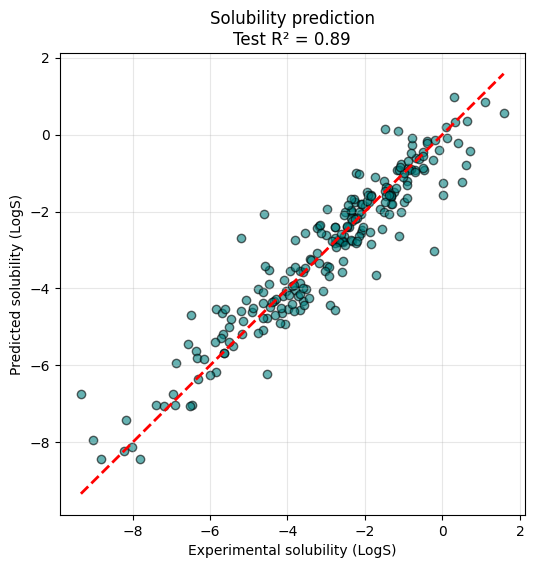

In [11]:
def pred_vs_exp_plot(y_test, y_test_pred, test_r2,):
  plt.figure(figsize=(6, 6))
  plt.scatter(y_test, y_test_pred, alpha=0.6, color='teal', edgecolors='k')

  min_val = min(y_test.min(), y_test_pred.min())
  max_val = max(y_test.max(), y_test_pred.max())
  plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2)

  plt.xlabel('Experimental solubility (LogS)')
  plt.ylabel('Predicted solubility (LogS)')
  plt.title(f'Solubility prediction\nTest R² = {test_r2:.2f}')
  plt.grid(True, alpha=0.3)
  plt.savefig("pred_vs_exp.png", dpi=200)
  plt.show()
pred_vs_exp_plot(results1['y_test'], results1['y_test_pred'], results1['test_r2'],)

In [12]:
from sklearn.model_selection import cross_val_score

def train_model_cv(X, y, model, cv = 5):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model.fit(X_train, y_train)

    y_test_pred = model.predict(X_test)
    test_r2 = r2_score(y_test, y_test_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

    cv_r2_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='r2')
    cv_mse_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='neg_mean_squared_error')
    cv_rmse_scores = np.sqrt(-cv_mse_scores)

    return {
        'model': model,
        'y_test': y_test,
        'y_test_pred': y_test_pred,
        'test_r2': test_r2,
        'test_rmse': test_rmse,
        'cv_r2_mean': cv_r2_scores.mean(),
        'cv_r2_std': cv_r2_scores.std(),
        'cv_rmse_mean': cv_rmse_scores.mean()
    }
results2 = train_model_cv(X, y, model) # 4 descriptors random split random forest cross val

print(f"Mean CV R²:   {results2['cv_r2_mean']:.3f} (± {results2['cv_r2_std']:.3f})")
print(f"Mean CV RMSE: {results2['cv_rmse_mean']:.3f}\n")

print(f"Test R²:      {results2['test_r2']:.3f}")
print(f"Test RMSE:    {results2['test_rmse']:.3f}")


Mean CV R²:   0.869 (± 0.009)
Mean CV RMSE: 0.755

Test R²:      0.888
Test RMSE:    0.697


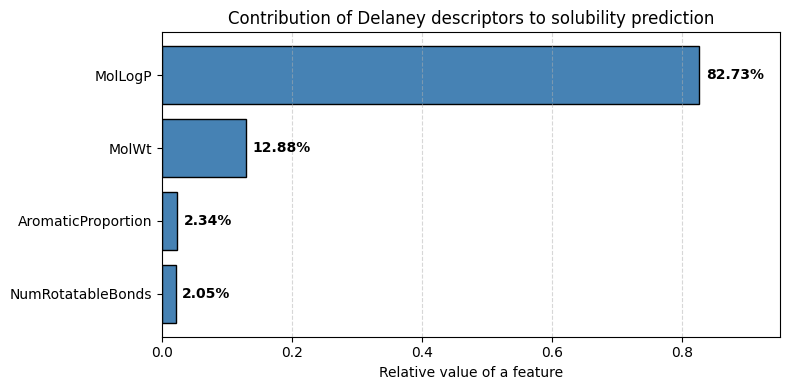

In [13]:
def plot_feature_importance(model, feature_names):
    importances = model.feature_importances_

    df_imp = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    }).sort_values(by='Importance', ascending=True)

    plt.figure(figsize=(8, 4))
    bars = plt.barh(df_imp['Feature'], df_imp['Importance'], color='steelblue', edgecolor='black')

    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.01, bar.get_y() + bar.get_height()/2,
                 f'{width:.2%}', va='center', fontsize=10, fontweight='bold')

    plt.xlim(0, max(importances) * 1.15)
    plt.xlabel('Relative value of a feature')
    plt.title('Contribution of Delaney descriptors to solubility prediction')
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig("feature_importance.png", dpi=200)
    plt.show()

plot_feature_importance(results1['model'], X.columns)


In [14]:
def predict_new_molecule(smiles, model):
    features_df = calculate_delaney_descriptors([smiles])
    predicted_logs = model.predict(features_df)[0]
    return predicted_logs

In [15]:
trained_model = results1['model']
test_molecules = [
    ("Caffeine", "CN1C=NC2=C1C(=O)N(C(=O)N2C)C"),
    ("Aspirin", "CC(=O)OC1=CC=CC=C1C(=O)O"),
    ("Paracetamol", "CC(=O)NC1=CC=C(C=C1)O"),
    ("Ibuprofen", "CC(C)CC1=CC=C(C=C1)C(C)C(=O)O"),
    ("Cholesterol", "CC(C)CCCC(C)C1CCC2C1(CCC3C2CC=C4C3(CCC(C4)O)C)C")
]
columns = ["Compound", "SMILES",]
new_molecules_predictions = pd.DataFrame(test_molecules, columns = columns)
log_s = []
for smiles in new_molecules_predictions["SMILES"]:
  log_s.append(predict_new_molecule(smiles, trained_model))
new_molecules_predictions["Predicted log S"] = log_s
new_molecules_predictions

,Compound,SMILES,Predicted log S
0,Caffeine,CN1C=NC2=C1C(=O)N(C(=O)N2C)C,-1.240590
1,Aspirin,CC(=O)OC1=CC=CC=C1C(=O)O,-1.903587
2,Paracetamol,CC(=O)NC1=CC=C(C=C1)O,-1.367450
3,Ibuprofen,CC(C)CC1=CC=C(C=C1)C(C)C(=O)O,-3.285357
4,Cholesterol,CC(C)CCCC(C)C1CCC2C1(CCC3C2CC=C4C3(CCC(C4)O)C)C,-7.486395


In [16]:
from rdkit.ML.Descriptors import MoleculeDescriptors

def calculate_all_rdkit_2d_descriptors(smiles_list):
    descriptor_names = [desc_name[0] for desc_name in Descriptors._descList]
    calculator = MoleculeDescriptors.MolecularDescriptorCalculator(descriptor_names)
    descriptors_data = []
    for smiles in smiles_list:
        mol = Chem.MolFromSmiles(smiles)
        descriptors_data.append(calculator.CalcDescriptors(mol))
    df_descriptors = pd.DataFrame(descriptors_data, columns=descriptor_names)
    return df_descriptors

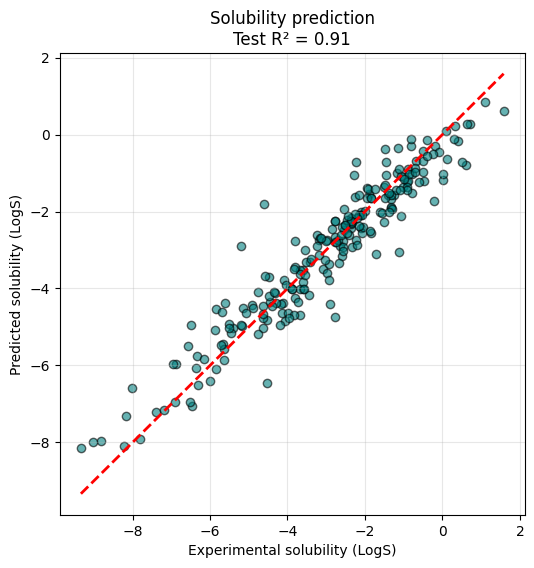

In [17]:
X = calculate_all_rdkit_2d_descriptors(df["SMILES"])
results3 = train_model_cv(X,y,model) # all descriptors random split random forest cross val
pred_vs_exp_plot(results3['y_test'], results3['y_test_pred'], results3['test_r2'])

In [18]:
!pip install xgboost


In [19]:
import xgboost as xgb
model = xgb.XGBRegressor() # all descriptors random split xgboost cross val

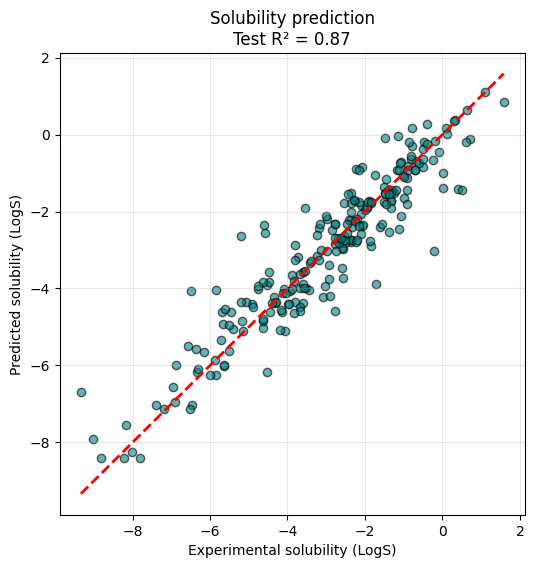

In [20]:
X = calculate_delaney_descriptors(df['SMILES'])
results4 = train_model_cv(X, y, model)
pred_vs_exp_plot(results4['y_test'], results4['y_test_pred'], results4['test_r2'])

In [21]:
from collections import defaultdict
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

def generate_scaffold(smiles, include_chirality=False):
    mol = Chem.MolFromSmiles(smiles)
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol, includeChirality=include_chirality
    )
    return scaffold

def scaffold_train_test_split(df, smiles_col, X, y, test_size=0.2):
    scaffolds = defaultdict(list)
    for idx, smiles in enumerate(df[smiles_col]):
        scaffold = generate_scaffold(smiles)
        scaffolds[scaffold].append(idx)

    scaffold_sets = sorted(
        scaffolds.values(),
        key=lambda x: (len(x), x[0]),
        reverse=True
    )

    train_cutoff = len(df) * (1 - test_size)
    train_idx, test_idx = [], []

    for scaffold_group in scaffold_sets:
        if len(train_idx) + len(scaffold_group) <= train_cutoff:
            train_idx.extend(scaffold_group)
        else:
            test_idx.extend(scaffold_group)

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    return X_train, X_test, y_train, y_test

def get_scaffold_groups(smiles_list, include_chirality=False):
    groups = []
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        scaffold = MurckoScaffold.MurckoScaffoldSmiles(
            mol=mol, includeChirality=include_chirality
        )

        if scaffold == "":
            groups.append(f"acyclic_{smi}")
        else:
            groups.append(scaffold)

    return np.array(groups)

def train_model_skaffold(X, y, model):

    X_tr, X_te, y_tr, y_te = scaffold_train_test_split(df, 'SMILES', X, y, test_size=0.2)


    model.fit(X_tr, y_tr)
    y_train_pred = model.predict(X_tr)
    y_test_pred = model.predict(X_te)


    test_r2 = r2_score(y_te, y_test_pred)
    test_mse = mean_squared_error(y_te, y_test_pred)

    train_groups = get_scaffold_groups(df.loc[X_tr.index, 'SMILES'])
    gkf = GroupKFold(n_splits=5)
    cv_r2_scores = cross_val_score(model, X_tr, y_tr, groups=train_groups, cv=gkf, scoring='r2')
    cv_rmse_scores = cross_val_score(model, X_tr, y_tr, groups=train_groups, cv=gkf, scoring='neg_root_mean_squared_error')

    result = {
        'model': model,
        'y_test': y_te,
        'y_train_pred': y_train_pred,
        'y_test_pred': y_test_pred,
        'test_r2': test_r2,
        'test_mse': test_mse,
        'cv_r2_mean': cv_r2_scores.mean(),
        'cv_r2_std': cv_r2_scores.std(),
        'cv_rmse_mean': -cv_rmse_scores.mean()
    }
    return result


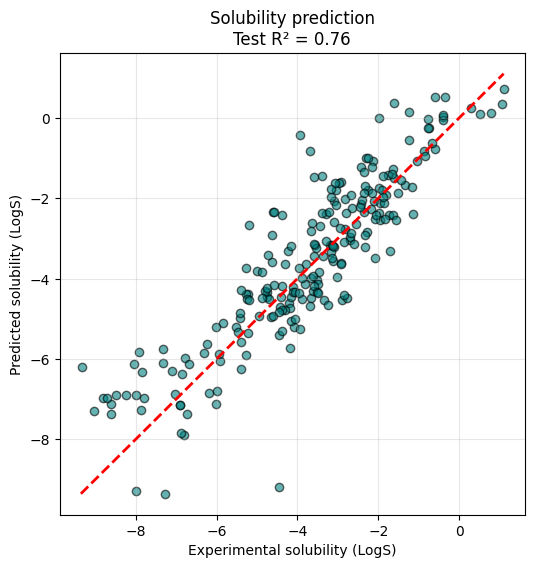

In [22]:
model = RandomForestRegressor()
X = calculate_delaney_descriptors(df['SMILES'])
results5 = train_model_skaffold(X, y, model) # 4 descriptors scaffold split random forest
pred_vs_exp_plot(results5['y_test'], results5['y_test_pred'], results5['test_r2'])

In [23]:
generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def generate_fingerprints(smiles_list):
  fp_list =[]
  for smiles in smiles_list:
    mol = Chem.MolFromSmiles(smiles)
    fp = generator.GetFingerprintAsNumPy(mol)
    fp_list.append(fp)
  col_names = [f'Morgan_{i}' for i in range(2048)]
  df_fps = pd.DataFrame(fp_list, columns=col_names)
  return df_fps

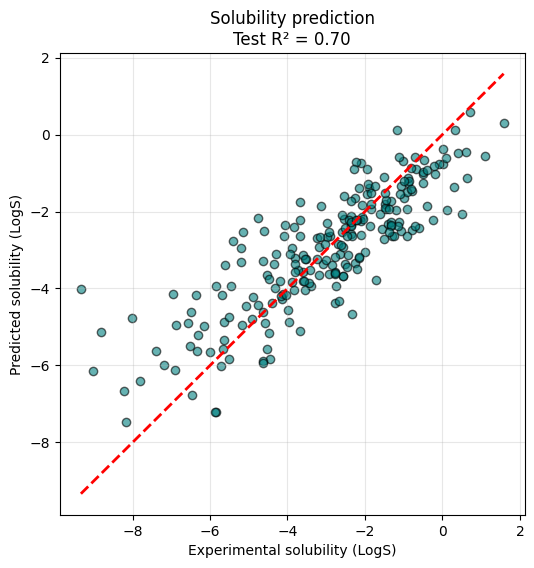

In [24]:
fps = generate_fingerprints(df["SMILES"])
results6 = train_model_cv(fps,y,model) # fingerprints random split xgboost cross val
pred_vs_exp_plot(results6['y_test'], results6['y_test_pred'], results6['test_r2'])

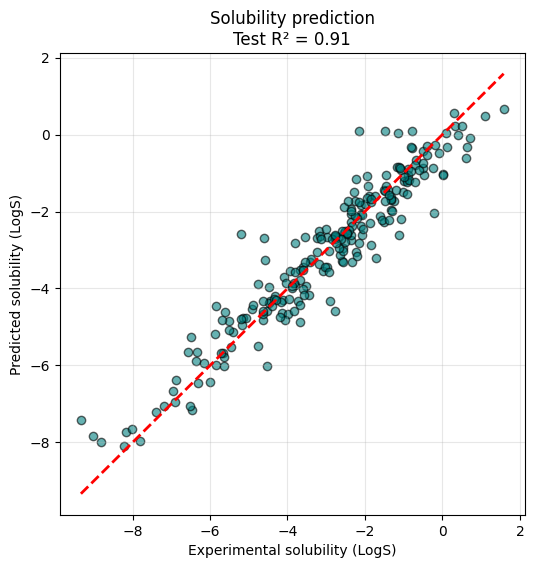

In [25]:
X = calculate_delaney_descriptors(df["SMILES"])
X_combined = pd.concat([X, fps], axis=1)
results7 = train_model_cv(X_combined,y,model)
pred_vs_exp_plot(results7['y_test'], results7['y_test_pred'], results7['test_r2'])

In [26]:
X_delaney = calculate_delaney_descriptors(df['SMILES'])
X_fp = generate_fingerprints(df['SMILES'])
X_combined = pd.concat([X_delaney, X_fp], axis=1)
X_all_2d = calculate_all_rdkit_2d_descriptors(df['SMILES'])

y = df['measured log(solubility:mol/L)']


experiments = [
    ("1. Baseline (Delaney 4 desc)", X_delaney, RandomForestRegressor(random_state=42), "Random"),
    ("2. Morgan Fingerprints (ECFP4)", X_fp, RandomForestRegressor(random_state=42), "Random"),
    ("3. Combined (Delaney + Morgan)", X_combined, RandomForestRegressor(random_state=42), "Random"),
    ("4. Full RDKit 2D (~200 desc)", X_all_2d, RandomForestRegressor(random_state=42), "Random"),
    ("5. Scaffold Split (Delaney 4 desc)", X_delaney, RandomForestRegressor(random_state=42), "Scaffold"),
    ("6. Scaffold Split (Full RDKit 2D)", X_all_2d, RandomForestRegressor(random_state=42), "Scaffold"),
    ("7. Baseline (Delaney 4 desc)", X_delaney, xgb.XGBRegressor(random_state=42), "Random"),
    ("8. Morgan Fingerprints (ECFP4)", X_fp, xgb.XGBRegressor(random_state=42), "Random"),
    ("9. Combined (Delaney + Morgan)", X_combined, xgb.XGBRegressor(random_state=42), "Random"),
    ("10. Full RDKit 2D (~200 desc)", X_all_2d, xgb.XGBRegressor(random_state=42), "Random"),
    ("11. Scaffold Split (Delaney 4 desc)", X_delaney, xgb.XGBRegressor(random_state=42), "Scaffold"),
    ("12. Scaffold Split (Full RDKit 2D)", X_all_2d, xgb.XGBRegressor(random_state=42), "Scaffold")
]

summary_rows = []

for name, X_curr, model, split_type in experiments:
    if split_type == "Random":
        X_tr, X_te, y_tr, y_te = train_test_split(X_curr, y, test_size=0.2, random_state=42)
        cv_r2_scores = cross_val_score(model, X_tr, y_tr, cv=5, scoring='r2')
        cv_rmse_scores = cross_val_score(model, X_tr, y_tr, cv=5, scoring='neg_root_mean_squared_error')
    else:
        X_tr, X_te, y_tr, y_te = scaffold_train_test_split(df, 'SMILES', X_curr, y, test_size=0.2)
        train_groups = get_scaffold_groups(df.loc[X_tr.index, 'SMILES'])
        gkf = GroupKFold(n_splits=5)
        cv_r2_scores = cross_val_score(model, X_tr, y_tr, groups=train_groups, cv=gkf, scoring='r2')
        cv_rmse_scores = cross_val_score(model, X_tr, y_tr, groups=train_groups, cv=gkf, scoring='neg_root_mean_squared_error')


    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    summary_rows.append({
        "Experiment": name,
        "Model": type(model).__name__,
        "Features": X_curr.shape[1],
        "Split": split_type,
        "CV R² (mean ± std)": f"{cv_r2_scores.mean():.3f} ± {cv_r2_scores.std():.2f}",
        "CV RMSE": round(- cv_rmse_scores.mean(), 3),
        "Test R²": round(r2_score(y_te, y_pred), 3),
        "Test RMSE": round(root_mean_squared_error(y_te, y_pred), 3)
    })
df_summary = pd.DataFrame(summary_rows)


In [27]:
df_summary

,Experiment,Model,Features,Split,CV R² (mean ± std),CV RMSE,Test R²,Test RMSE
0,1. Baseline (Delaney 4 desc),RandomForestRegressor,4,Random,0.870 ± 0.01,0.753,0.890,0.692
1,2. Morgan Fingerprints (ECFP4),RandomForestRegressor,2048,Random,0.656 ± 0.06,1.220,0.698,1.146
2,3. Combined (Delaney + Morgan),RandomForestRegressor,2052,Random,0.881 ± 0.01,0.722,0.904,0.648
3,4. Full RDKit 2D (~200 desc),RandomForestRegressor,217,Random,0.895 ± 0.01,0.677,0.908,0.634
4,5. Scaffold Split (Delaney 4 desc),RandomForestRegressor,4,Scaffold,0.785 ± 0.10,0.892,0.751,1.034
5,6. Scaffold Split (Full RDKit 2D),RandomForestRegressor,217,Scaffold,0.831 ± 0.08,0.781,0.813,0.896
6,7. Baseline (Delaney 4 desc),XGBRegressor,4,Random,0.855 ± 0.01,0.796,0.873,0.745
7,8. Morgan Fingerprints (ECFP4),XGBRegressor,2048,Random,0.668 ± 0.05,1.200,0.722,1.099
8,9. Combined (Delaney + Morgan),XGBRegressor,2052,Random,0.882 ± 0.01,0.719,0.900,0.659
9,10. Full RDKit 2D (~200 desc),XGBRegressor,217,Random,0.883 ± 0.01,0.715,0.904,0.648
